# 03 · Vitals classifier vs NEWS2 vs triage nurse

Can a small model on vitals + basic patient facts spot urgent patients better than the NEWS2 formula?

- **Main output:** `p_urgent`, the probability that the experts would triage the patient KTAS 1–2.
- **Secondary:** a predicted KTAS level 1–5, to compare with the triage nurse.
- **Inputs:** only what the app will have: vitals, consciousness, pain score, age, sex, injury (`vitals_classifier.FEATURES`).
  The chief complaint is left out on purpose: reading the patient's story is the main language model's job.

**Protocol.** The validation set alone holds only 32 urgent patients, too few to choose settings reliably. So
model settings and the alert threshold are chosen by **5-fold cross-validation on the development set (train + val)**.
The **test set is used once**, at the end, for every number that is reported.

In [1]:
import sys, json, datetime
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, roc_curve, brier_score_loss,
                             cohen_kappa_score, accuracy_score, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import ktas_data as kd
import news2
import vitals_classifier as vc

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
ROOT = Path.cwd().parent
FIG_DIR, MODEL_DIR = ROOT / "figures", ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
SEED = 0

## 1. Data, features and targets

In [2]:
df = kd.load_clean()
assert "split" in df.columns, "run notebook 02 first (it writes splits.csv)"
X_all = vc.build_X(df)
df["news2"] = X_all["news2"]
df["urgent"] = vc.urgent_target(df)
df["news2_floor"] = news2.score_frame(df)["floor_priority"].to_numpy()

dev, test = df[df.split != "test"], df[df.split == "test"]
X_dev, X_test = X_all.loc[dev.index], X_all.loc[test.index]
y_dev, y_test = dev.urgent, test.urgent
print(f"development: {len(dev)} visits, {y_dev.sum()} urgent | test: {len(test)} visits, {y_test.sum()} urgent")
print("features:", vc.FEATURES)
X_all.isna().mean().mul(100).round(1).rename("% missing").to_frame().T

development: 1072 visits, 208 urgent | test: 190 visits, 37 urgent
features: ['age', 'is_male', 'injured', 'mental', 'nrs_pain', 'sbp', 'dbp', 'hr', 'rr', 'temp_c', 'spo2', 'news2']


,age,is_male,injured,mental,nrs_pain,sbp,dbp,hr,rr,temp_c,spo2,news2
% missing,0.0,0.0,0.0,0.0,0.2,2.0,2.3,1.6,1.7,1.3,54.9,0.0


## 2. Choose model settings by cross-validation (development set only)

Two model types: logistic regression (simple, easy to explain) and gradient-boosted trees (handle missing values natively
and capture non-linear effects such as "both too low and too high is bad"). NEWS2 needs no fitting and is shown for reference.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_auc(model):
    aucs = []
    for tr, va in cv.split(X_dev, y_dev):
        m = clone(model).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        aucs.append(roc_auc_score(y_dev.iloc[va], vc.urgent_proba(m, X_dev.iloc[va])))
    return np.mean(aucs), np.std(aucs)

configs = [("logreg", {"C": C}) for C in [0.01, 0.1, 1, 10]]
configs += [("hgb", {"max_depth": d, "learning_rate": lr, "max_iter": n, "min_samples_leaf": leaf})
            for d in [2, 3] for lr in [0.03, 0.1] for n in [100, 300] for leaf in [20, 40]]
makers = {"logreg": vc.make_logreg, "hgb": vc.make_hgb}

rows = []
for name, params in configs:
    mean, sd = cv_auc(makers[name](**params))
    rows.append({"model": name, "params": params, "cv_auroc": round(mean, 3), "sd": round(sd, 3)})
news2_folds = [roc_auc_score(y_dev.iloc[va], X_dev.news2.iloc[va]) for _, va in cv.split(X_dev, y_dev)]
rows.append({"model": "NEWS2 (no fitting)", "params": {}, "cv_auroc": round(np.mean(news2_folds), 3),
             "sd": round(np.std(news2_folds), 3)})
cv_table = pd.DataFrame(rows).sort_values("cv_auroc", ascending=False).reset_index(drop=True)
cv_table

,model,params,cv_auroc,sd
0,hgb,"{'max_depth': 3, 'learning_rate': 0.03, 'max_i...",0.830,0.050
1,hgb,"{'max_depth': 3, 'learning_rate': 0.1, 'max_it...",0.828,0.050
2,hgb,"{'max_depth': 2, 'learning_rate': 0.03, 'max_i...",0.821,0.047
3,hgb,"{'max_depth': 2, 'learning_rate': 0.1, 'max_it...",0.821,0.049
4,hgb,"{'max_depth': 3, 'learning_rate': 0.03, 'max_i...",0.821,0.051
5,hgb,"{'max_depth': 2, 'learning_rate': 0.1, 'max_it...",0.819,0.048
6,hgb,"{'max_depth': 3, 'learning_rate': 0.1, 'max_it...",0.816,0.043
7,hgb,"{'max_depth': 2, 'learning_rate': 0.1, 'max_it...",0.814,0.037
8,hgb,"{'max_depth': 2, 'learning_rate': 0.03, 'max_i...",0.812,0.040
9,hgb,"{'max_depth': 2, 'learning_rate': 0.03, 'max_i...",0.811,0.051


In [4]:
best = {name: cv_table[cv_table.model == name].iloc[0] for name in makers}
chosen = max(best, key=lambda n: best[n].cv_auroc)
print("best per type:", {n: (dict(b.params), b.cv_auroc) for n, b in best.items()})
print("chosen for the app (highest CV AUROC):", chosen)

best per type: {'logreg': ({'C': 0.01}, np.float64(0.804)), 'hgb': ({'max_depth': 3, 'learning_rate': 0.03, 'max_iter': 300, 'min_samples_leaf': 20}, np.float64(0.83))}
chosen for the app (highest CV AUROC): hgb


## 3. Alert threshold (development set, out-of-fold)

`p_urgent` above the threshold raises the patient's safety floor to priority 3. The threshold is set so that
**80% of urgent patients** in the development set would be flagged, using out-of-fold predictions (each patient scored
by a model that never saw them).

In [5]:
TARGET_SENS = 0.80
oof = {n: cross_val_predict(makers[n](**best[n].params), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
       for n in makers}
p_oof = oof[chosen]
threshold = float(np.quantile(p_oof[y_dev == 1], 1 - TARGET_SENS))
flag = p_oof >= threshold
print(f"threshold = {threshold:.3f}  ->  dev sensitivity {flag[y_dev == 1].mean():.2f}, "
      f"specificity {(~flag[y_dev == 0]).mean():.2f}, flags {flag.mean():.0%} of visits")

threshold = 0.140  ->  dev sensitivity 0.80, specificity 0.69, flags 41% of visits


## 4. Final models, evaluated once on the test set

In [6]:
final = {n: makers[n](**best[n].params).fit(X_dev, y_dev) for n in makers}
p_test = {n: vc.urgent_proba(m, X_test) for n, m in final.items()}

scores = {
    "NEWS2": test.news2.to_numpy(),
    "Logistic regression": p_test["logreg"],
    "Gradient boosting": p_test["hgb"],
    "Triage nurse (KTAS_RN)": -test.ktas_nurse.to_numpy(),   # lower KTAS = more urgent
}
rows = []
for name, s in scores.items():
    auc, lo, hi = vc.bootstrap(roc_auc_score, y_test, s)
    rows.append({"method": name, "AUROC": round(auc, 3), "95% CI": f"{lo:.2f}-{hi:.2f}"})
auc_table = pd.DataFrame(rows)

chosen_label = {"logreg": "Logistic regression", "hgb": "Gradient boosting"}[chosen]
d, lo, hi = vc.bootstrap(roc_auc_score, y_test, scores[chosen_label], scores["NEWS2"])
print(f"{chosen_label} minus NEWS2: AUROC difference {d:+.3f} (95% CI {lo:+.3f} to {hi:+.3f}, paired bootstrap)")
auc_table

Gradient boosting minus NEWS2: AUROC difference +0.085 (95% CI -0.002 to +0.169, paired bootstrap)


,method,AUROC,95% CI
0,NEWS2,0.694,0.58-0.79
1,Logistic regression,0.790,0.70-0.87
2,Gradient boosting,0.779,0.68-0.86
3,Triage nurse (KTAS_RN),0.915,0.84-0.97


### Operating points on the test set

Sensitivity and specificity for KTAS 1–2 at the threshold chosen on the development set, next to NEWS2's
official trigger and the nurse (nurse "flags" = nurse triaged KTAS 1–2).

In [7]:
def op(name, flag):
    flag, y = np.asarray(flag), y_test.to_numpy()
    return {"rule": name, "flagged": int(flag.sum()),
            "sensitivity": round(flag[y == 1].mean(), 2), "specificity": round((~flag[y == 0]).mean(), 2)}

op_table = pd.DataFrame([
    op("NEWS2 >= 5 (official urgent trigger)", test.news2 >= 5),
    op("NEWS2 >= 3", test.news2 >= 3),
    op(f"{chosen_label} p >= {threshold:.2f}", p_test[chosen] >= threshold),
    op("Triage nurse KTAS 1-2", test.ktas_nurse <= 2),
])
op_table

,rule,flagged,sensitivity,specificity
0,NEWS2 >= 5 (official urgent trigger),14,0.27,0.97
1,NEWS2 >= 3,31,0.49,0.92
2,Gradient boosting p >= 0.14,93,0.81,0.59
3,Triage nurse KTAS 1-2,35,0.84,0.97


### Calibration

If the note says "82% chance urgent", that number should mean something. Brier score (lower is better) and observed
vs predicted rates by fifths of predicted risk, on the test set.

In [8]:
p = p_test[chosen]
print(f"Brier score {brier_score_loss(y_test, p):.3f}  (always predicting the base rate: "
      f"{brier_score_loss(y_test, np.full(len(p), y_dev.mean())):.3f})")
bins = pd.qcut(p, 5, duplicates="drop")
pd.DataFrame({"mean predicted": pd.Series(p).groupby(bins, observed=True).mean(),
              "observed urgent": pd.Series(y_test.to_numpy()).groupby(bins, observed=True).mean(),
              "n": pd.Series(p).groupby(bins, observed=True).size()}).round(2)

Brier score 0.116  (always predicting the base rate: 0.157)


,mean predicted,observed urgent,n
"(0.011, 0.0441]",0.03,0.08,38
"(0.0441, 0.0873]",0.06,0.03,38
"(0.0873, 0.174]",0.14,0.18,38
"(0.174, 0.309]",0.22,0.18,38
"(0.309, 0.984]",0.56,0.50,38


## 5. Predicting the full KTAS level (1–5)

A 5-class gradient-boosting model, settings chosen by cross-validated quadratic weighted kappa (QWK) on the
development set. QWK measures agreement on an ordered scale (1 = perfect, 0 = chance) and penalises big misses more.
Under-triage = predicted less urgent than the experts.

In [9]:
y5_dev, y5_test = dev.ktas_expert, test.ktas_expert
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for d_ in [2, 3]:
    for n in [100, 300]:
        for cw in [None, "balanced"]:
            m = vc.make_hgb(max_depth=d_, learning_rate=0.05, max_iter=n).set_params(class_weight=cw)
            pred = cross_val_predict(m, X_dev, y5_dev, cv=cv5)
            rows.append({"max_depth": d_, "max_iter": n, "class_weight": cw,
                         "cv_qwk": round(cohen_kappa_score(y5_dev, pred, weights="quadratic"), 3)})
qwk_table = pd.DataFrame(rows).sort_values("cv_qwk", ascending=False).reset_index(drop=True)
b5 = qwk_table.iloc[0]
cw5 = b5.class_weight if isinstance(b5.class_weight, str) else None   # pandas may store None as NaN
model5 = vc.make_hgb(max_depth=int(b5.max_depth), learning_rate=0.05, max_iter=int(b5.max_iter)) \
    .set_params(class_weight=cw5).fit(X_dev, y5_dev)
pred5 = model5.predict(X_test)
qwk_table.head(4)

,max_depth,max_iter,class_weight,cv_qwk
0,3,100,NaN,0.446
1,3,300,NaN,0.434
2,2,100,NaN,0.428
3,2,300,balanced,0.422


In [10]:
def level_metrics(name, pred):
    pred, y = np.asarray(pred), y5_test.to_numpy()
    q, lo, hi = vc.bootstrap(lambda a, b: cohen_kappa_score(a, b, weights="quadratic"), y, pred)
    return {"method": name, "exact agreement": round(accuracy_score(y, pred), 3),
            "QWK": round(q, 3), "QWK 95% CI": f"{lo:.2f}-{hi:.2f}",
            "under-triage": round((pred > y).mean(), 3), "over-triage": round((pred < y).mean(), 3)}

pd.DataFrame([level_metrics("Vitals model (5-class)", pred5),
              level_metrics("Triage nurse (KTAS_RN)", test.ktas_nurse)])

,method,exact agreement,QWK,QWK 95% CI,under-triage,over-triage
0,Vitals model (5-class),0.626,0.406,0.22-0.56,0.184,0.189
1,Triage nurse (KTAS_RN),0.884,0.848,0.76-0.92,0.079,0.037


In [11]:
pd.DataFrame(confusion_matrix(y5_test, pred5, labels=[1, 2, 3, 4, 5]),
             index=[f"expert {k}" for k in range(1, 6)], columns=[f"model {k}" for k in range(1, 6)])

,model 1,model 2,model 3,model 4,model 5
expert 1,2,2,0,0,0
expert 2,0,12,11,10,0
expert 3,0,5,56,12,0
expert 4,0,3,17,49,0
expert 5,1,0,7,3,0


## 6. Combined safety floor

Floor from NEWS2 alone (notebook 02) versus NEWS2 **plus** the classifier (`p_urgent` ≥ threshold → floor 3).
Over-triage = floor more urgent than the experts' level. Test set.

A floor is only a minimum urgency, so it can never make a patient *less* urgent: any under-triage in the final ranking
comes from the main model, not from the floor.

In [12]:
clf_floor = np.where(p_test[chosen] >= threshold, 3, 5)
combined_floor = np.minimum(test.news2_floor.to_numpy(), clf_floor)

def floor_stats(name, floor):
    urgent, expert = y_test.to_numpy() == 1, test.ktas_expert.to_numpy()
    return {"floor from": name,
            "urgent patients given a floor": f"{(urgent & (floor <= 3)).sum()} / {urgent.sum()}",
            "over-triaged visits": f"{(floor < expert).sum()} / {len(floor)}"}

pd.DataFrame([floor_stats("NEWS2 only", test.news2_floor.to_numpy()),
              floor_stats("NEWS2 + classifier", combined_floor)])

,floor from,urgent patients given a floor,over-triaged visits
0,NEWS2 only,15 / 37,3 / 190
1,NEWS2 + classifier,30 / 37,28 / 190


## 7. What drives the classifier?

Permutation importance on the test set: how much AUROC drops when one input is shuffled (30 repeats).

In [13]:
imp = permutation_importance(final[chosen], X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED)
importance = (pd.DataFrame({"feature": vc.FEATURES, "AUROC drop": imp.importances_mean, "sd": imp.importances_std})
              .sort_values("AUROC drop", ascending=False).round(4).reset_index(drop=True))
importance

,feature,AUROC drop,sd
0,news2,0.0750,0.0210
1,spo2,0.0291,0.0216
2,sbp,0.0096,0.0143
3,dbp,0.0093,0.0074
4,injured,0.0083,0.0069
5,age,0.0075,0.0173
6,mental,0.0034,0.0044
7,is_male,0.0032,0.0033
8,nrs_pain,0.0018,0.0035
9,rr,-0.0000,0.0028


## 8. Figures for the report

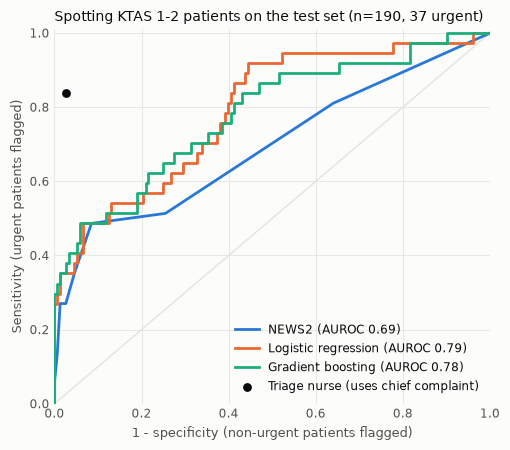

In [14]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {"NEWS2": "#2a78d6", "Logistic regression": "#eb6834", "Gradient boosting": "#1baf7a"}

fig, ax = plt.subplots(figsize=(5.2, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot([0, 1], [0, 1], color=GRID, lw=1, zorder=0)
for name, color in SERIES.items():
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    auc = auc_table.set_index("method").loc[name, "AUROC"]
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUROC {auc:.2f})")
nurse = test.ktas_nurse <= 2
nx, ny = (~nurse[y_test == 0]).mean(), nurse[y_test == 1].mean()
ax.scatter([1 - nx], [ny], s=70, color=INK, edgecolor=SURFACE, linewidth=2, zorder=5,
           label="Triage nurse (uses chief complaint)")
ax.set_xlabel("1 - specificity (non-urgent patients flagged)", color=MUTED, fontsize=9)
ax.set_ylabel("Sensitivity (urgent patients flagged)", color=MUTED, fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
ax.grid(color=GRID, lw=0.6)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=8.5, labelcolor=INK)
ax.set_title(f"Spotting KTAS 1-2 patients on the test set (n={len(test)}, {y_test.sum()} urgent)",
             loc="left", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_test.png", dpi=300, facecolor=SURFACE)
plt.show()

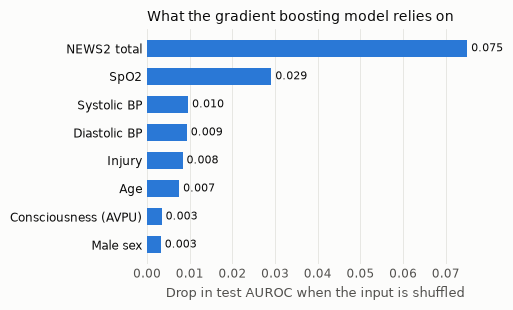

In [15]:
top = importance.head(8).iloc[::-1]
NICE = {"age": "Age", "is_male": "Male sex", "injured": "Injury", "mental": "Consciousness (AVPU)",
        "nrs_pain": "Pain score", "sbp": "Systolic BP", "dbp": "Diastolic BP", "hr": "Heart rate",
        "rr": "Respiratory rate", "temp_c": "Temperature", "spo2": "SpO2", "news2": "NEWS2 total"}
fig, ax = plt.subplots(figsize=(5.2, 3.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.barh([NICE[f] for f in top.feature], top["AUROC drop"], color="#2a78d6", height=0.6)
for i, v in enumerate(top["AUROC drop"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8, color=INK)
ax.set_xlabel("Drop in test AUROC when the input is shuffled", color=MUTED, fontsize=9)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
ax.tick_params(axis="y", colors=INK)
ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title(f"What the {chosen_label.lower()} model relies on", loc="left", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_importance.png", dpi=300, facecolor=SURFACE)
plt.show()

## 9. Save the models for the app

The deployed models are refitted on **all** labelled data (development + test) with the settings and threshold chosen
above. This is standard once evaluation is finished: the test numbers above describe the method, and the final model
simply sees more patients.

In [16]:
X_full, y_full = X_all, df.urgent
deploy_urgent = makers[chosen](**best[chosen].params).fit(X_full, y_full)
deploy_level = clone(model5).fit(X_full, df.ktas_expert)
joblib.dump(deploy_urgent, MODEL_DIR / "urgent_model.joblib")
joblib.dump(deploy_level, MODEL_DIR / "ktas_level_model.joblib")

meta = {
    "created": datetime.date.today().isoformat(),
    "features": vc.FEATURES,
    "urgent_definition": "ktas_expert <= 2",
    "urgent_model": {"type": chosen, "params": {k: (v.item() if hasattr(v, "item") else v)
                                                for k, v in dict(best[chosen].params).items()},
                     "cv_auroc_dev": float(best[chosen].cv_auroc)},
    "level_model": {"max_depth": int(b5.max_depth), "max_iter": int(b5.max_iter),
                    "class_weight": cw5, "cv_qwk_dev": float(b5.cv_qwk)},
    "threshold": round(threshold, 4),
    "threshold_rule": f"flags {TARGET_SENS:.0%} of urgent patients (dev, out-of-fold)",
    "floor_if_flagged": 3,
    "test_results": {
        "auroc": auc_table.set_index("method")["AUROC"].to_dict(),
        "n_test": int(len(test)), "n_test_urgent": int(y_test.sum()),
    },
    "versions": {"sklearn": sklearn.__version__, "pandas": pd.__version__},
    "split_seed": 42,
}
(MODEL_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))

pd.DataFrame({"visit_id": test.visit_id, "ktas_expert": test.ktas_expert, "urgent": y_test,
              "news2": test.news2, "p_urgent": p_test[chosen], "pred_ktas": pred5,
              "news2_floor": test.news2_floor, "combined_floor": combined_floor}) \
  .to_csv(kd.PROCESSED_DIR / "test_predictions.csv", index=False)
print(sorted(p.name for p in MODEL_DIR.iterdir()))
print(json.dumps(meta, indent=2))

['ktas_level_model.joblib', 'model_meta.json', 'urgent_model.joblib']
{
  "created": "2026-10-18",
  "features": [
    "age",
    "is_male",
    "injured",
    "mental",
    "nrs_pain",
    "sbp",
    "dbp",
    "hr",
    "rr",
    "temp_c",
    "spo2",
    "news2"
  ],
  "urgent_definition": "ktas_expert <= 2",
  "urgent_model": {
    "type": "hgb",
    "params": {
      "max_depth": 3,
      "learning_rate": 0.03,
      "max_iter": 300,
      "min_samples_leaf": 20
    },
    "cv_auroc_dev": 0.83
  },
  "level_model": {
    "max_depth": 3,
    "max_iter": 100,
    "class_weight": null,
    "cv_qwk_dev": 0.446
  },
  "threshold": 0.1401,
  "threshold_rule": "flags 80% of urgent patients (dev, out-of-fold)",
  "floor_if_flagged": 3,
  "test_results": {
    "auroc": {
      "NEWS2": 0.694,
      "Logistic regression": 0.79,
      "Gradient boosting": 0.779,
      "Triage nurse (KTAS_RN)": 0.915
    },
    "n_test": 190,
    "n_test_urgent": 37
  },
  "versions": {
    "sklearn": "1.9.1"

## Summary for the report

(Numbers from the run of 18 Oct 2026, split seed 42. Re-check them if the data or settings change.)

- **Model choice (development set, 5-fold CV AUROC for KTAS 1–2):** gradient boosting 0.83, logistic regression 0.80,
  NEWS2 0.69. Gradient boosting was chosen on this basis, before the test set was used.
- **Test set (190 visits, 37 urgent):** AUROC NEWS2 0.69 (95% CI 0.58–0.79), logistic regression 0.79 (0.70–0.87),
  gradient boosting 0.78 (0.68–0.86), triage nurse 0.92 (0.84–0.97). Gradient boosting minus NEWS2 = +0.085
  (95% CI −0.002 to +0.169): a consistent gain, but the small test set cannot rule out no difference.
  Logistic regression edging gradient boosting on test is within noise.
- **At the chosen threshold (p ≥ 0.14):** sensitivity 0.81, specificity 0.59 on test, versus 0.27 / 0.97 for the official
  NEWS2 trigger (≥ 5) and 0.84 / 0.97 for the nurse. The classifier finds far more urgent patients than NEWS2, at the cost
  of more false alarms.
- **Probabilities are usable:** Brier score 0.116 versus 0.157 for always guessing the base rate; predicted and
  observed rates agree within a few points across risk fifths.
- **The 5-level prediction is weak:** QWK 0.41 versus 0.85 for the nurse, 18% under-triage, and it never predicts KTAS 5.
  Do not use it as the triage decision; pass `p_urgent` to the main model instead.
- **Combined safety floor:** adding the classifier raises urgent patients given a floor from 15 to 30 of 37, while
  over-triaged visits rise from 3 to 28 of 190 (15%). This is a trade-off the group should decide on.
- **What the model uses:** NEWS2 total and SpO2 matter most; the other inputs' importances are within their own noise.
- **Main message:** vitals alone reach AUROC ≈ 0.8, the nurse with the chief complaint ≈ 0.9. The gap is what the
  patient's history adds, which is the job of the main language model.